# COVID Vaccine Allocation: Minimising Town Cost (Dataset C)
### Data Science Challenge Hackathon, 11 November 2026, Group S

**GitHub organisation:** https://github.com/Team-S-Hackathon-Group-RM  
**Repository:** https://github.com/Team-S-Hackathon-Group-RM/Team-S-Hackathon-Group-RM
**Open in Colab:** https://colab.research.google.com/github/Team-S-Hackathon-Group-RM/Team-S-Hackathon-Group-RM/blob/main/FINAL%20GroupS%20TownCost.ipynb  
**Shared Colab (Editor):** to be added by the team

### Team members (Group S)
| # | Name | Notebook sections / role |
|---|---|---|
| 1 | Maruri Siva Harshitha | 2 EDA |
| 2 | Shruthi Chintalapudi | 2 EDA |
| 3 | Iqra Fazal | 3 Metric + AI hospitalisation research |
| 4 | Aqsa Iqbal | 4 Pre-processing, 5.1 |
| 5 | Kodi Chinthala Vaishnavi | 5–6 Models + calibration |
| 6 | Shravani Mukkarigari | 7–8 Tuning + ensemble |
| 7 | Lakshmi Nagaraju Manthri | 9 Results, variability, sensitivity |
| 8 | Varun Kumar Kashetty | 11–12 XAI, critical analysis, slides |
| 9 | Sai Raghavendra Ummareddy | absent from the hackathon on 11 Nov; no sections assigned |

**The task.** For every resident in the test set, decide whether to **post them a COVID vaccine (1) or not (0)**.
We are scored on the **total money the town spends**, not on accuracy:

* Vaccine: **$1,500** per dose sent (a dose nobody uses is wasted but still paid for).
* Anyone who wants a vaccine but is not sent one must be paid **$1,500 in cash** instead (and stays unvaccinated).
* Everyone is infected (100%). Each hospitalisation costs **$41,000**. The hospitalisation risk depends on the person and on whether they are vaccinated.

**Plan of the notebook**
1. Setup and data
2. Exploratory data analysis (EDA)
3. The task metric (town cost) and the optimal decision rule
4. Pre-processing (two variants)
5. Models, scored with repeated cross-validation (mean ± std)
6. Probability calibration
7. Hyper-parameter tuning
8. Ensemble
9. Decision rule comparison and sensitivity to the hospitalisation assumptions
10. Final ranking and the 5 submission files
11. Explainable AI (first version)
12. Critical analysis

*Integrator (sections 1 and 10, GitHub setup, Canvas upload): one of the members above, to be chosen by the team.*

## 0. Team guidelines (read first)

**Deadline today: upload to Canvas at 15:40** (hard deadline 16:00), assignment *"Data Science Challenge Hackathon submissions"*: the 5 files in `submission/` + link to the GitHub organisation + link to this Colab.

### Who does what (suggested split; change if the team decides otherwise)
| Pair | Sections of this notebook | Task |
|---|---|---|
| Integrator: ____ (choose one) | 1, 10 | GitHub/Colab setup, final *Restart and run all* at 15:15, submission files, Canvas upload |
| EDA: Maruri Siva Harshitha & Shruthi Chintalapudi | 2 | more plots that justify pre-processing and model choices |
| Metric: Iqra Fazal | 3 | ask 2–3 different AIs for hospitalisation probabilities, fill the table in 3.3 and the values in the code |
| Pre-processing: Aqsa Iqbal | 4, 5.1 | try other options (binning, imputation, encoding), compare with the town cost |
| Models: Kodi Chinthala Vaishnavi | 5, 6 | add models (e.g. XGBoost, MLP), scored with `evaluate()` |
| Tuning / ensemble: Shravani Mukkarigari · Results: Lakshmi Nagaraju Manthri | 7, 8, 9 | tuning, variability (box plot, paired comparison), sensitivity |
| XAI + slides: Varun Kumar Kashetty | 11, 12 | XAI for **all** models, figure styling, presentation (may continue after 16:00) |

### Rules for working in this shared notebook
1. Work only in **your own section**. Add new cells inside it, never in someone else's.
2. Put your name in every markdown heading you add, e.g. `### 2.6 Income vs vaccination (YourName)`.
3. **Do not press Run all** while others are working. Run your own cells (run sections 1, 3 and 4 once first, so `train`, `X`, `y`, `hosp_probs` and `evaluate` exist).
4. Every model must be scored with **`evaluate()`**: town cost per resident, mean ± std over the same 15 CV folds. Never rank by accuracy, F1 or AUC alone.
5. Every plot that will go in the slides must be produced by code in this notebook (1 point lost per plot without code).
6. Explain each step in a markdown cell: **what** you did and **why**.
7. After finishing a piece of work, push it to GitHub **from your own account**: *File → Save a copy in GitHub* → org repo, path `FINAL GroupS TownCost.ipynb`, branch `main`, message saying what you did (e.g. `Pre-processing: binning comparison (YourName)`). Commit every 30–45 min.
8. After 16:00 only **XAI and figure styling** may change. No new models or pre-processing.

### Timeline today
| Time | Milestone |
|---|---|
| by 11:45 | GitHub org + public repo + Colab shared (Editor) + names filled in above |
| by 12:30 | AI hospitalisation answers in 3.3 |
| 12:30–15:00 | each pair extends its sections and pushes |
| 15:00 | stop adding models; everything must be scored with `evaluate()` |
| 15:15 | integrator: *Runtime → Restart and run all*, check 5 files, push notebook with outputs |
| **15:40** | **Canvas upload** (second person confirms) |

### Submission requirements (checked automatically in section 10)
* 5 **different** files, named `challenge_submission_group_S_order_1.csv` … `_order_5.csv`, order 1 = lowest town cost.
* Same format as `dataset_C_example_submission.csv`: columns `respondent_id`, `covid_vaccine` (1 = send a vaccine, 0 = don't), all 4,749 test IDs in the same order.

### For the presentation (Tue 17 Nov; slides due 10:00, talks from 13:00)
* Slide 1: **GitHub organisation URL + this Colab URL**.
* 10 minutes hard stop, then 5 min questions; **every member presents** and must be able to answer questions on the **whole** project.
* Must include: model architecture and training scheme, EDA, performance with the town cost, XAI, successes and failures, how we divided work and made decisions, and **one slide for non-experts** (plain language, no jargon).

Full details: `docs/HOW_TO_PUSH.md` (**step-by-step push instructions for every member**), `docs/CHECKLIST.md` (every requirement) and `docs/GITHUB_GUIDE.md` (GitHub workflow).

## 1. Setup and data

> 👤 **Section owner:** Integrator: ____ (choose one)  
> 📌 **Section rules:** Only the integrator edits this section. Keep `SEED = 42`. Do not change file names or the `GITHUB_DATA` link.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Setup:` and ends with your name.

## 5. Models scored with repeated cross-validation
Every model is evaluated with **5-fold stratified CV repeated 3 times (15 folds)**. In each fold we fit on 4/5 of the data, predict acceptance probabilities on the held-out 1/5, apply the personal-threshold rule and compute the **town cost per resident**.
The spread over the 15 folds (std) tells us how large random variation is, so we only trust differences between models that are bigger than this noise.

> 👤 **Section owner:** Kodi Chinthala Vaishnavi  
> 📌 **Section rules:** Add each new model to the `models` dict and score it **only with `evaluate()`** (same 15 folds, town cost mean ± std). Do not rank by accuracy, F1 or AUC alone. Keep `random_state=SEED`.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Models:` and ends with your name.

In [ ]:
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

def evaluate(pipe, X=X, y=y, cv=CV):
    """Fold-wise town cost per resident (personal thresholds) and at a 0.5 cut-off, plus AUC and log loss."""
    rows, oof, cnt = [], np.zeros(len(y)), np.zeros(len(y))
    for tr, va in cv.split(X, y):
        m = clone(pipe).fit(X.iloc[tr], y[tr])
        q = m.predict_proba(X.iloc[va])[:, 1]
        pu, pv = PU[va], PV[va]
        rows.append({'cost': town_cost(y[va], decide(q, pu, pv), pu, pv) / len(va),
                     'cost_at_0.5': town_cost(y[va], q >= 0.5, pu, pv) / len(va),
                     'auc': roc_auc_score(y[va], q), 'logloss': log_loss(y[va], q)})
        oof[va] += q; cnt[va] += 1
    return pd.DataFrame(rows), oof / cnt

models = {
    'LogisticRegression': Pipeline([('p', pre_A), ('m', LogisticRegression(C=0.3, max_iter=4000))]),
    'RandomForest': Pipeline([('p', pre_B_imputed), ('m', RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                max_features='sqrt', n_jobs=-1, random_state=SEED))]),
    'HistGradientBoosting': Pipeline([('p', pre_B), ('m', HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                max_leaf_nodes=31, min_samples_leaf=30, l2_regularization=1.0,
                                categorical_features=CAT_IDX, random_state=SEED))]),
    'LightGBM': Pipeline([('p', pre_B), ('m', LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15,
                                min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                reg_lambda=1.0, random_state=SEED, verbose=-1))]),
}
folds, OOF = {}, {}
for name, pipe in models.items():
    folds[name], OOF[name] = evaluate(pipe)
    f = folds[name]
    print(f"{name:22s} cost/resident ${f.cost.mean():,.0f} ± {f.cost.std():,.0f} | AUC {f.auc.mean():.4f} | logloss {f.logloss.mean():.4f}")

LogisticRegression     cost/resident $3,235 ± 106 | AUC 0.8637 | logloss 0.4248
RandomForest           cost/resident $3,235 ± 107 | AUC 0.8582 | logloss 0.4346
HistGradientBoosting   cost/resident $3,252 ± 110 | AUC 0.8501 | logloss 0.4556
LightGBM               cost/resident $3,230 ± 101 | AUC 0.8601 | logloss 0.4273


### 5.1 Pre-processing comparison
Same model (logistic regression) and the same 15 folds, so each option can be compared **fold by fold** with the baseline (variant A):
* without missing-value indicators (missingness imputed away);
* without the two engineered features (`behavioral_count`, `doc_x_risk`).

In [ ]:
pre_A_simple = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), CAT)])
f_simple, _ = evaluate(Pipeline([('p', pre_A_simple), ('m', LogisticRegression(C=0.3, max_iter=4000))]))
ENGINEERED = ['behavioral_count', 'doc_x_risk']
pre_A_noeng = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())]), [c for c in NUM if c not in ENGINEERED]),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='missing')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), CAT)])
f_noeng, _ = evaluate(Pipeline([('p', pre_A_noeng), ('m', LogisticRegression(C=0.3, max_iter=4000))]))

base = folds['LogisticRegression'].cost
for label, f in [('missing imputed away', f_simple), ('no engineered features', f_noeng)]:
    d = f.cost - base
    print(f"{label:24s}: ${f.cost.mean():,.0f} ± {f.cost.std():,.0f} | paired extra ${d.mean():+,.1f} per resident vs baseline, "
          f"baseline cheaper in {(d > 0).sum()}/15 folds")

missing imputed away    : $3,270 ± 100 | paired extra $+35.5 per resident vs baseline, baseline cheaper in 15/15 folds
no engineered features  : $3,234 ± 106 | paired extra $-1.2 per resident vs baseline, baseline cheaper in 4/15 folds


## 6. Probability calibration
The decision rule uses the probabilities directly, so they must be *calibrated* (a predicted 0.3 should mean 30% accept). We check the reliability curve and test isotonic calibration on the boosting model.

> 👤 **Section owner:** Kodi Chinthala Vaishnavi  
> 📌 **Section rules:** The decision rule uses probabilities directly, so check every new model's reliability curve. Calibrate with `CalibratedClassifierCV` inside CV only.  
> 🔁 **Always:** Work only inside this section · put your name in every heading you add · run your own cells, never *Run all* while others work · push after each finished piece (File → Save a copy in GitHub, same file path). Commit message starts with `Calibration:` and ends with your name.

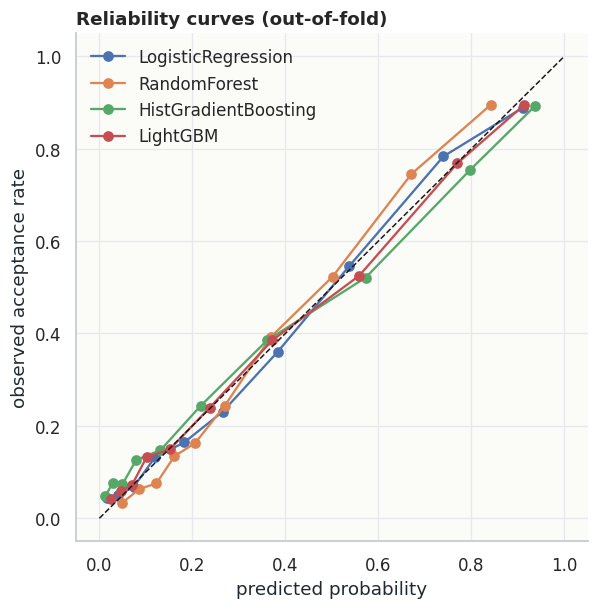

HGB_calibrated cost/resident $3,248 ± 109 | logloss 0.4401


In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
for name in OOF:
    frac, mean_p = calibration_curve(y, OOF[name], n_bins=10, strategy='quantile')
    ax.plot(mean_p, frac, 'o-', label=name)
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_xlabel('predicted probability'); ax.set_ylabel('observed acceptance rate')
ax.set_title('Reliability curves (out-of-fold)'); ax.legend(); plt.show()

models['HGB_calibrated'] = CalibratedClassifierCV(models['HistGradientBoosting'], method='isotonic', cv=3)
folds['HGB_calibrated'], OOF['HGB_calibrated'] = evaluate(models['HGB_calibrated'])
f = folds['HGB_calibrated']
print(f"HGB_calibrated cost/resident ${f.cost.mean():,.0f} ± {f.cost.std():,.0f} | logloss {f.logloss.mean():.4f}")